# Tópicos por período legal

Este notebook responde: **sobre o que falam os anúncios, e isso muda ao longo do século XIX?**
Usamos o modelo de tópicos `t5` (corpus `corp3`, campos `c5`), já gravado no banco compartilhado do grupo.
O modelo antigo `t4` (6 tópicos) aparece só na seção 8, para comparação.


Cada gráfico vem com uma ou duas frases dizendo o que ele mostra. Os números dessas frases foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca**, não por sorteio. O que aparece aqui descreve
> o que a busca encontrou, não todos os anúncios do século XIX. Os **nomes** dos tópicos são **hipóteses do grupo**, não fatos.

## 1. O que é um tópico e por que k = 6
**Um tópico é um grupo de palavras que costumam aparecer juntas nos mesmos anúncios.** O programa (LDA) não lê o sentido:
ele só agrupa palavras. Quem dá nome ao grupo somos nós, olhando as palavras e os anúncios.

**Por que 6 tópicos (k = 6)?** Rodamos o modelo várias vezes com sementes diferentes (ver `scripts/estabilidade_topicos.py`)
e medimos quantos tópicos **se repetem** (similaridade de cosseno ≥ 0,8). Com k = 4, 56% dos tópicos se repetem; com k = 6, 59%;
com k = 8, 50%; com k = 10, 29%; com k = 12, 44%. Não cai de forma regular, mas k = 10 é o pior. Mantemos k = 6 (e não k = 4) para separar mais temas. Mesmo em k = 8, quatro temas se repetem muito bem nas
sementes: fuga (0,93), serviço doméstico (0,90), ama de leite (0,85) e aluguel de homens (0,81).
**O resultado também depende da semente do sorteio:** com uma semente fixa, 3 anúncios a mais já reorganizaram todos os tópicos. Por isso usamos a semente mais representativa entre 10.
Ou seja, a estabilidade é **moderada**: os resultados abaixo são pistas, não medidas exatas.

## Preparação: ler o banco
O banco devolve no máximo 1000 linhas por consulta, então lemos em blocos (paginação).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hdb import config
from hdb.banco import BancoSupabase

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
db = BancoSupabase().cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

MODELO = config.VERSAO_TOPICOS
COMPARA = "t4"
palavras = ler_tudo(lambda: db.table("topico_palavras").select("versao,topico,palavra,peso")
                    .in_("versao", [MODELO, COMPARA]).order("versao").order("topico").order("peso", desc=True))
dist = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao")
                .eq("versao", MODELO).order("anuncio_id").order("topico"))
anuncios = ler_tudo(lambda: db.table("anuncios_completos")
                    .select("id,periodo_legal,c_tipo,c_sexo,c_idade_min,c_idade_max,ano,texto")
                    .in_("versao", list(config.VERSOES_ANUNCIOS)).eq("c_versao", config.VERSAO_CAMPOS).order("id"))
print(f"{dist['anuncio_id'].nunique()} anúncios no modelo {MODELO}; {len(anuncios)} anúncios com campos {config.VERSAO_CAMPOS} no banco")

2191 anúncios no modelo t5; 34693 anúncios com campos c5 no banco


In [2]:
PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]

# Nomes SUGERIDOS (hipóteses do grupo): o LDA numera os tópicos ao acaso, então hdb.topicos.nomear dá a cada tópico
# o nome (de topicos.REFERENCIAS) cujas palavras mais aparecem entre as suas 12 de maior peso.
from hdb.topicos import REFERENCIAS, nomear
NOMES = nomear({t: g.sort_values("peso", ascending=False)["palavra"].head(12) for t, g in palavras[palavras.versao == MODELO].groupby("topico")})
K = len(NOMES)
rot = lambda t: f"T{t} {NOMES[t]}"

# Uma linha por anúncio do modelo, com o tópico dominante
pivo = dist.pivot(index="anuncio_id", columns="topico", values="proporcao")
base = anuncios.drop_duplicates("id").set_index("id").join(pivo, how="inner")
base["dominante"] = base[list(range(K))].idxmax(axis=1)
base["periodo"] = pd.Categorical(base["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)
print(len(base), "anúncios na base de análise")
if len(base) != 2191:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2191 anúncios e agora são {len(base)}: "
          "confira os números dos textos antes de usar.")

# Paleta Okabe-Ito, uma cor por tópico
CORES = ["#0072B2", "#D55E00", "#E69F00", "#009E73", "#CC79A7", "#999999"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

2191 anúncios na base de análise


## 2. Os tópicos do modelo `t5`
Abaixo, as **12 palavras de maior peso** de cada tópico (as palavras estão sem acento, como no corpus padronizado).
A coluna **Nome sugerido** é uma **proposta provisória**: o grupo precisa confirmar ou trocar.

In [3]:
tab = (palavras[palavras["versao"] == MODELO].groupby("topico")["palavra"].apply(lambda s: ", ".join(s.head(12))))
tabela = pd.DataFrame({"Nome sugerido": [NOMES[t] for t in tab.index], "12 palavras de maior peso": tab.values},
                      index=pd.Index(tab.index, name="Tópico"))
tabela

,Nome sugerido,12 palavras de maior peso
Tópico,,
0,Aluguel de pretos e moleques para todo o serviço,"aluga, preto, servico, todo, pretas, precisa, duas, alugao, moleque, bom, alugar, dois"
1,"Fuga: nome, idade e dono","dia, nome, corrente, preto, fugiu, anos, idade, nacao, escravo, sera, camisa, vestido"
2,Venda com preço e qualidades,"vende, preto, anos, bom, cozinheiro, aluga, boa, perfeito, preta, forno, moleque, escravos"
3,"Mulheres: lavar, engomar, cozinhar (aluguel e venda)","preta, aluga, lava, vende, lavar, cozinha, servico, engomar, engoma, cozinhar, bem, sabe"
4,Fuga: roupa levada e nação,"nome, fugiu, dia, escravo, nacao, levar, corrente, anos, preto, idade, sera, bem"
5,Ama de leite,"leite, ama, aluga, boa, preta, bom, meses, vende, carinhosa, cria, parto, primeiro"


**Nomes sugeridos (provisórios), dados pelas palavras de cada tópico; o número do tópico muda a cada rodada, o nome acompanha o conteúdo.** Dois tópicos são **fuga** e juntos têm 436 dos 447 anúncios de fuga (97,5%): **roupa levada e nação** (`fugiu`, `nacao`, `levar`, `corrente`: 304 fugas) e **nome, idade e dono** (`nome`, `idade`, `camisa`, `vestido`: 132 fugas); os dois descrevem o mesmo gênero e se distinguem pouco. **Ama de leite** (`leite`, `ama`, `meses`, `carinhosa`, `parto`) tem 175 das 237 amas de leite (74%). Dois tópicos são de serviço doméstico: **mulheres que lavam, engomam e cozinham** (`lava`, `lavar`, `cozinha`, `engoma`, `sabe`), que reúne 425 dos 852 aluguéis e 205 vendas, e **aluguel de pretos e moleques para todo o serviço** (`aluga`, `servico`, `todo`, `moleque`, `alugao`: 242 aluguéis e 63 vendas). **Venda com preço e qualidades** (`vende`, `perfeito`, `cozinheiro`, `forno`, `escravos`) tem 294 das 619 vendas.

## 3. Os 3 anúncios mais típicos de cada tópico
São os 3 com **maior proporção** daquele tópico. Mostramos os primeiros 250 caracteres do texto original.
Serve para conferir se o nome sugerido faz sentido.

In [4]:
for t in range(K):
    print(f"=== Tópico {t}: {NOMES[t]} ===")
    top3 = base.sort_values(t, ascending=False).head(3)
    for i, r in top3.iterrows():
        txt = " ".join(str(r["texto"]).split())[:250]
        print(f"  [id {i}, {r['periodo']}, tipo {r['c_tipo']}, proporção {r[t]:.2f}] {txt}")
    print()

=== Tópico 0: Aluguel de pretos e moleques para todo o serviço ===
  [id 6351, 1831–1850, tipo venda, proporção 0.98] VENDE-SE hum preto bom cozinheiro, na rua do Hospicio n. 24, — A. TAVEL c A. F. ZIESE fazem sciento a esta praça que, na data de koje, dissolvêrão amigavelmente a sociedade que tinhão nella com a firma de TAVEL E ZIESE, ficando encarregado da liquida
  [id 31291, 1850–1871, tipo aluguel, proporção 0.96] LUGA-SE um moleque copeiro, e tambem se aluga da frente de um sobrado outro para todo o serviço; na rua do Cano n. bo. mens; para iaformações, = É uma pesto quo lava, cagomena 6 fas com "OS &. 35. 1/2 wma esa qu va ngomnas fas co Pd ção todo o serviç
  [id 33735, 1831–1850, tipo venda, proporção 0.96] VENDEM-SE infallivelmente a quem mais der, por estar para retirar se brevemente uma familia, algumas pretas prendadas, negrinhas que ja podem fazer algum serviço, é um preto bom official de calufate quem os pretender dirija-se à rua Nova de, Fran. ci

=== Tópico 1: Fuga: no

**Leitura dos exemplos** (3 por tópico, os mais típicos). Combinam com o nome: as fugas de roupa e nação (ids 6433, 13930, 5967) e de nome e idade (ids 6263, 29624), as vendas de mulheres (ids 13759, 38080, 29501), a venda com preço e qualidades (ids 6146, 10107), o aluguel de moleques (id 31291) e a ama de leite (id 32041). **Discordâncias:** (a) um dos três típicos de fuga (id 14286, "PUBLICAÇÕES A PEDIDO. OS PAQUETES DE VAPOR") **não é anúncio de pessoa**; (b) dois típicos do tema de aluguel de pretos e moleques são **vendas** (ids 6351 e 33735), o que mostra que esse tema também mistura venda; (c) dois típicos de ama de leite são **vendas de uma ama** (ids 29128 e 36129), com o texto muito estragado pelo OCR. **Auditoria mais ampla:** li os 10 anúncios mais típicos de cada tópico em duas rodadas (rótulos de Claude). Na segunda, em anúncios que as regras não tinham visto, **6 de 52 (11,5%) ainda eram problema**: um anúncio de rapé, um cavalo escrito "cavalio", um extrato policial de presos, uma cópia de decreto, uma venda de engenho e uma máquina colada à frente de um anúncio de pessoa. A meta de no máximo 2 em 30 **não foi atingida**; o lixo que sobra é de muitos tipos pequenos (cauda longa), e cada rodada de ajuste acha outros. As regras para decreto, extrato, fumo e "cavalio" foram acrescentadas **depois** dessa medida e **não foram medidas em anúncios novos**.

## 4. Peso de cada tópico por período legal
Para cada período, a **proporção média** de cada tópico nos anúncios daquele período (cada coluna soma 100%).

               T0 Aluguel de pretos e moleques para todo o serviço  T1 Fuga: nome, idade e dono  T2 Venda com preço e qualidades  T3 Mulheres: lavar, engomar, cozinhar (aluguel e venda)  T4 Fuga: roupa levada e nação  T5 Ama de leite     n
periodo                                                                                                                                                                                                                                        
antes de 1831                                                  5.3                         14.9                              8.3                                                     22.7                           31.4             17.4   152
1831–1850                                                     13.4                          9.4                             22.5                                                     25.6                           14.7             14.4   565
1850–1871                               

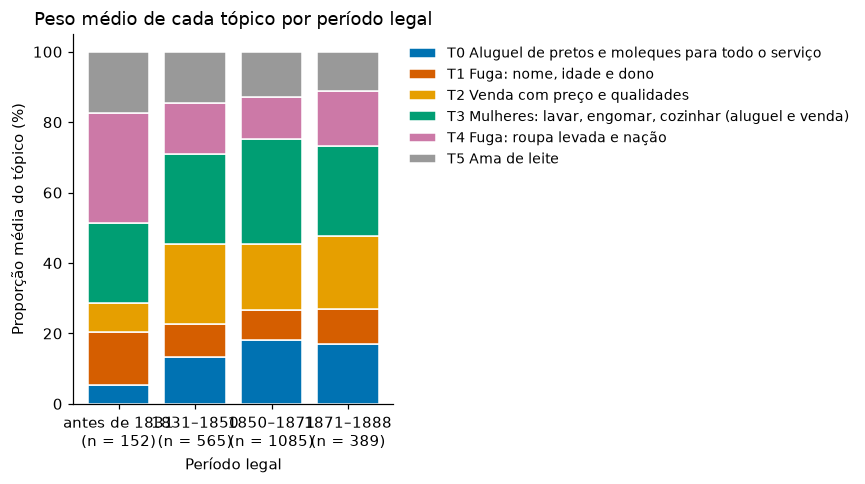

In [5]:
media = base.groupby("periodo", observed=True)[list(range(K))].mean().reindex(PERIODOS)
n_per = base.groupby("periodo", observed=True).size().reindex(PERIODOS)
med = (media * 100).round(1)
med.columns = [rot(t) for t in med.columns]
print(med.assign(n=n_per).to_string())
print("\nComposição por tipo em cada período (% dos anúncios):")
print((pd.crosstab(base["periodo"], base["c_tipo"], normalize="index") * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
fundo = np.zeros(len(PERIODOS))
for t in range(K):
    ax.bar(range(len(PERIODOS)), media[t].values * 100, bottom=fundo, color=CORES[t], edgecolor="white", label=rot(t))
    fundo += media[t].values * 100
ax.set_xticks(range(len(PERIODOS)))
ax.set_xticklabels([f"{p}\n(n = {n_per[p]})" for p in PERIODOS])
ax.set_title("Peso médio de cada tópico por período legal")
ax.set_xlabel("Período legal"); ax.set_ylabel("Proporção média do tópico (%)")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()

**O que se vê:** os dois tópicos de **fuga somados** caem de 46,3% antes de 1831 para 24,1% em 1831–1850, 20,5% em 1850–1871 e 25,2% em 1871–1888 (a alta no último período vem das páginas de 1887, que são só de fuga). O tema de **mulheres que lavam, engomam e cozinham** sobe de 22,7% a 25,6% e 29,9% e recua a 25,8%; o de **aluguel de pretos e moleques** vai de 5,3% a 13,4%, 18,2% e 17,0%. Somados, os dois temas de serviço vão de 28,0% a 39,0%, 48,1% e 42,8%: **crescem até 1850–1871 e depois ficam estáveis**. **Venda com preço e qualidades** vai de 8,3% a 22,5% (1831–1850) e fica em 18,6% e 20,7%. **Ama de leite** cai de 17,4% a 11,2%. **Cuidado:** a composição por tipo muda muito: fuga é 44,7% do corpus antes de 1831 e 23,9% em 1871–1888 (era 16,4% em 1850–1871), enquanto aluguel vai de 11,8% a 28,1%, 45,5% e 46,5%. Como o tópico acompanha o tipo (seção 7), parte do que parece mudança nos temas vem de **quantos anúncios de cada tipo a busca achou** em cada período. **Ressalva (caderno `robustez_mistura`):** igualando a mistura de tipos entre os períodos, essas parcelas ficam quase planas (serviço doméstico entre 41% e 48%, sem alta), então **a queda da fuga e a alta do serviço doméstico acima são, em boa parte, mistura de tipos**, não mudança de conteúdo.

## 5. Por sexo
Aqui o tópico entra como **proporção média** entre os anúncios de cada sexo (`f` ou `m`).

> **Ressalva:** o sexo vem de **palavras do anúncio** ("preta", "preto", "moleque"…), e o tipo "ama de leite" é feminino
> **por construção**. Por isso, depois do gráfico, cruzamos **tipo × sexo** e **tipo × tópico** para separar o que
> é efeito do tipo.

{'Feminino': 1063, 'Masculino': 859}
c_sexo                                                   Feminino  Masculino
T0 Aluguel de pretos e moleques para todo o serviço          10.7       23.1
T1 Fuga: nome, idade e dono                                   5.2       13.6
T2 Venda com preço e qualidades                              10.9       28.9
T3 Mulheres: lavar, engomar, cozinhar (aluguel e venda)      46.2        7.4
T4 Fuga: roupa levada e nação                                 6.0       21.6
T5 Ama de leite                                              21.0        5.4


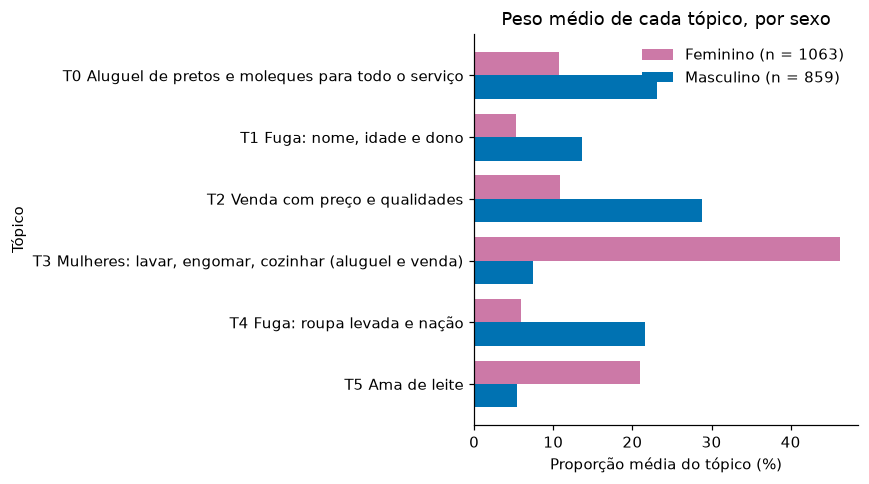

In [6]:
sx = base[base["c_sexo"].isin(["f", "m"])]
n_sx = sx.groupby("c_sexo").size()
m_sx = sx.groupby("c_sexo")[list(range(K))].mean().T * 100
m_sx.index = [rot(t) for t in m_sx.index]
m_sx = m_sx.rename(columns={"f": "Feminino", "m": "Masculino"})
print((n_sx.rename({"f": "Feminino", "m": "Masculino"})).to_dict())
print(m_sx.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(K); h = 0.38
ax.barh(y - h/2, m_sx["Feminino"].values, h, color="#CC79A7", label=f"Feminino (n = {n_sx.get('f', 0)})")
ax.barh(y + h/2, m_sx["Masculino"].values, h, color="#0072B2", label=f"Masculino (n = {n_sx.get('m', 0)})")
ax.set_yticks(y); ax.set_yticklabels(m_sx.index); ax.invert_yaxis()
ax.set_title("Peso médio de cada tópico, por sexo"); ax.set_xlabel("Proporção média do tópico (%)"); ax.set_ylabel("Tópico")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

In [7]:
# O sexo é efeito do tipo? Tipo x sexo (contagem) e tipo x tópico médio (%)
print(pd.crosstab(base["c_tipo"], base["c_sexo"].fillna("não diz")).to_string())
print()
por_tipo = base.groupby("c_tipo")[list(range(K))].mean() * 100
por_tipo.columns = [f"T{t}" for t in por_tipo.columns]
print(por_tipo.round(1).assign(n=base.groupby("c_tipo").size()).to_string())
print()
# Dentro de um mesmo tipo, f e m diferem? (fuga e venda são os tipos com os dois sexos)
for tipo in ["fuga", "venda"]:
    s = sx[sx["c_tipo"] == tipo]
    if s["c_sexo"].nunique() == 2:
        d = (s.groupby("c_sexo")[list(range(K))].mean() * 100).round(1)
        d.columns = [f"T{t}" for t in d.columns]
        print(f"Tipo {tipo}: n =", s.groupby("c_sexo").size().to_dict()); print(d.to_string()); print()

c_sexo        ambos    f    m  não diz
c_tipo                                
aluguel          47  507  297        1
ama_de_leite     21  209    5        2
compra            7   13   16        0
fuga             17   69  271       90
venda            83  265  270        1

                T0    T1    T2    T3    T4    T5    n
c_tipo                                               
aluguel       26.6   3.5  15.9  42.7   3.5   7.8  852
ama_de_leite   7.9   4.3   6.8  13.8   3.5  63.7  237
compra        15.2   5.8  28.3  29.4   2.3  19.0   36
fuga           2.9  31.0   2.6   3.3  57.1   3.0  447
venda         13.4   4.2  40.1  29.4   4.1   8.8  619

Tipo fuga: n = {'f': 69, 'm': 271}
         T0    T1   T2   T3    T4   T5
c_sexo                                
f       2.4  34.0  2.5  8.1  49.4  3.6
m       2.6  32.4  2.6  1.9  57.7  2.7

Tipo venda: n = {'f': 265, 'm': 270}
          T0   T1    T2    T3   T4    T5
c_sexo                                  
f        8.7  3.4  21.9  51.2  2.9  

**O que se vê:** entre mulheres (n = 1.063) pesa muito o tema de mulheres que lavam, engomam e cozinham (46,2%) e a ama de leite (21,0%); entre homens (n = 859) pesam a venda com preço e qualidades (28,9%), o aluguel de pretos e moleques (23,1%) e a fuga por roupa e nação (21,6%). **Em parte é efeito do tipo:** quase todo anúncio de ama de leite é feminino (209 `f` contra 5 `m`) e a fuga é majoritariamente masculina (271 `m` contra 69 `f`). Dentro da **fuga** a diferença é pequena: o tema de roupa e nação pesa 49,4% nas mulheres e 57,7% nos homens. Já dentro da **venda** ela **permanece**: nas mulheres pesa o tema de lavar, engomar e cozinhar (51,2%), e nos homens a venda com preço e qualidades (55,7%, contra 21,9% nas mulheres). Com n de 265 e 270, é um sinal razoável, mas ainda uma **pista**.

## 6. Por faixa de idade
Só entram anúncios que **dizem a idade** (usamos o ponto médio quando há intervalo). O número é pequeno,
então **as diferenças entre faixas são frágeis**: veja o `n` de cada linha antes de tirar conclusões.

In [8]:
base["idade"] = base[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
FAIXAS = ["até 12", "13–20", "21–35", "36+"]
base["faixa"] = pd.cut(base["idade"], bins=[-1, 12, 20, 35, 200], labels=FAIXAS)
com_idade = base[base["idade"].notna()]
print(f"{len(com_idade)} de {len(base)} anúncios têm idade")
ti = com_idade.groupby("faixa", observed=True)[list(range(K))].mean() * 100
ti.columns = [f"T{t}" for t in ti.columns]
ti.insert(0, "n", com_idade.groupby("faixa", observed=True).size())
ti.round(1)

360 de 2191 anúncios têm idade


,n,T0,T1,T2,T3,T4,T5
faixa,,,,,,,
até 12,39,12.7,10.0,40.0,16.6,8.3,12.3
13–20,186,12.4,10.8,29.3,23.9,15.5,8.1
21–35,94,3.4,19.2,18.1,14.3,35.9,9.1
36+,41,7.3,16.6,23.5,9.9,35.4,7.4


**Fragilidade:** só 360 dos 2.191 anúncios dizem a idade, e as faixas têm n = 39, 186, 94 e 41. Os tópicos de **fuga** somados pesam 18,3% até 12 anos, 26,3% de 13 a 20, **55,1% de 21 a 35** e 52,0% de 36 em diante: **quem tem idade registrada na fuga é, em geral, adulto**. **Crianças** aparecem sobretudo em venda: até 12 anos, a venda com preço e qualidades pesa 40,0%, e de 13 a 20 anos, 29,3%. São diferenças frágeis: a idade só aparece quando o OCR a leu e a faixa até 12 anos tem 39 anúncios.

## 7. Tópico × tipo de anúncio
Cada anúncio vai para o seu **tópico dominante** (o de maior proporção). A matriz conta quantos anúncios de cada tipo
caem em cada tópico. Se cada tópico fosse "só" um tipo, haveria um bloco forte por coluna.

               T0   T1   T2   T3   T4   T5  Total
c_tipo                                           
aluguel       242   10  119  425   11   45    852
ama_de_leite   13    2   11   30    6  175    237
compra          4    1   13   12    0    6     36
fuga            4  132    2    3  304    2    447
venda          63    8  294  205   10   39    619
Total         326  153  439  675  331  267   2191


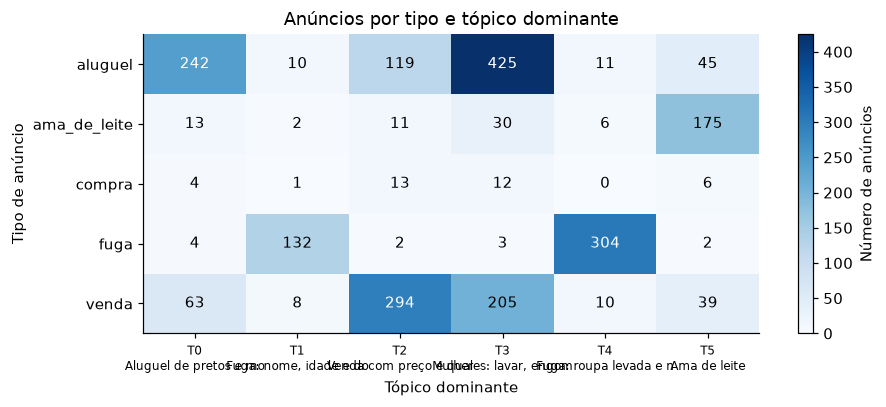

In [9]:
tt = pd.crosstab(base["c_tipo"], base["dominante"])
tt.columns = [f"T{t}" for t in tt.columns]
tt["Total"] = tt.sum(axis=1)
tt.loc["Total"] = tt.sum()
print(tt.to_string())

mat = pd.crosstab(base["c_tipo"], base["dominante"]).reindex(columns=range(K), fill_value=0)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(mat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(K)); ax.set_xticklabels([f"T{t}\n{NOMES[t][:22]}" for t in range(K)], fontsize=8)
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(K):
        v = mat.values[i, j]
        ax.text(j, i, str(v), ha="center", va="center", color="white" if v > mat.values.max() * 0.5 else "black")
ax.set_title("Anúncios por tipo e tópico dominante"); ax.set_xlabel("Tópico dominante"); ax.set_ylabel("Tipo de anúncio")
fig.colorbar(im, ax=ax, label="Número de anúncios")
fig.tight_layout(); plt.show()

**O que se vê:** os tópicos **acompanham bastante o tipo**: 436 dos 447 anúncios de fuga (97,5%) estão nos dois tópicos de fuga; 175 das 237 amas de leite no de ama de leite (74%); 425 dos 852 aluguéis no tema de mulheres que lavam e cozinham e 242 no de aluguel de pretos e moleques; e a venda se divide entre a venda com preço e qualidades (294) e o tema de mulheres (205). Então, em boa medida, os tópicos **são os tipos** (o modelo não descobriu muito além do que a classificação já dizia). O que os tópicos acrescentam está nas **palavras** (a fuga se descreve pela roupa e pela nação, as mulheres pelo que sabem fazer, os homens pelo ofício e pelo preço).

## 8. Comparação com o modelo `t4`
Para cada tópico de `t4`, buscamos o tópico de `t5` mais parecido pela **similaridade de cosseno** entre as distribuições de palavras.

> **Aproximação:** o banco guarda só as **12 palavras de maior peso** de cada tópico. Usamos a união dessas palavras
> como vocabulário e **peso 0** para as ausentes. O resultado é aproximado e ignora a cauda de cada tópico.

In [10]:
pal = palavras.pivot_table(index=["versao", "topico"], columns="palavra", values="peso", fill_value=0)
M2, M3 = pal.loc[COMPARA], pal.loc[MODELO]
vocab = sorted(set(M2.columns) | set(M3.columns))
A = M2.reindex(columns=vocab, fill_value=0).values
B = M3.reindex(columns=vocab, fill_value=0).values
cos = (A / np.linalg.norm(A, axis=1, keepdims=True)) @ (B / np.linalg.norm(B, axis=1, keepdims=True)).T
linhas = []
for i, antigo in enumerate(M2.index):
    j = int(cos[i].argmax())
    linhas.append({"Tópico do modelo antigo": antigo, "Palavras do modelo antigo": ", ".join(palavras[(palavras.versao == COMPARA) & (palavras.topico == antigo)]["palavra"].head(6)) + "…",
                   "Mais parecido no modelo novo": f"T{M3.index[j]} {NOMES[M3.index[j]]}", "Cosseno": round(float(cos[i, j]), 2)})
pd.DataFrame(linhas).set_index("Tópico do modelo antigo")

,Palavras do modelo antigo,Mais parecido no modelo novo,Cosseno
Tópico do modelo antigo,,,
0,"dia, fugiu, nome, corrente, nacao, levar…",T4 Fuga: roupa levada e nação,0.96
1,"preto, vende, bom, anos, aluga, cozinheiro…",T2 Venda com preço e qualidades,0.93
2,"aluga, preta, leite, ama, servico, precisa…",T5 Ama de leite,0.71
3,"escravo, rio, queira, dias, cidade, fugido…",T4 Fuga: roupa levada e nação,0.23
4,"anos, vende, moleque, idade, senhora, qualquer…",T2 Venda com preço e qualidades,0.58
5,"preta, lava, aluga, cozinha, engoma, vende…","T3 Mulheres: lavar, engomar, cozinhar (aluguel e venda)",0.93


**O que se vê:** os temas claros do modelo antigo (`t4`, antes da limpeza) têm par no novo com cosseno alto: fuga com o de roupa e nação em **0,96**, venda e aluguel de homens com venda com preço e qualidades em **0,93**, serviço doméstico com o tema de mulheres em **0,93**, e aluguel de mulheres e ama de leite com ama de leite em **0,71**. **O tópico fraco de avisos misturados do modelo antigo não tem par** (0,23, com a fuga de roupa e nação), e o de venda de moleques e colunas mistas casa só em **0,58**. Isso indica que **a limpeza removeu o ruído que formava esses tópicos**. A perplexidade (829, contra 946 no modelo antigo) não é uma comparação direta, porque o corpus mudou. É uma comparação **aproximada** (só 12 palavras por tópico).

## 9. E se os aluguéis duvidosos entrassem? (variante `t5i`)
O `aluguel_incerto` são anúncios de aluguel em que o texto **não diz** se a pessoa era escravizada ("precisa-se de uma criada").
Eles ficam fora do modelo principal. Aqui ajustamos o mesmo modelo **com** eles (`t5i`) e comparamos a parcela de cada tema por período.
Os temas recebem o nome pelo mesmo critério de palavras, então a comparação é pelo **nome**, não pelo número.

In [11]:
VARIANTE = MODELO + "i"
pal_i = ler_tudo(lambda: db.table("topico_palavras").select("versao,topico,palavra,peso").eq("versao", VARIANTE)
                 .order("topico").order("peso", desc=True))
dist_i = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao").eq("versao", VARIANTE)
                  .order("anuncio_id").order("topico"))
nomes_i = nomear({t: g.sort_values("peso", ascending=False)["palavra"].head(12) for t, g in pal_i.groupby("topico")})
pivo_i = dist_i.pivot(index="anuncio_id", columns="topico", values="proporcao").rename(columns=nomes_i)
com_i = anuncios.drop_duplicates("id").set_index("id")[["periodo_legal"]].join(pivo_i, how="inner")
com_i["periodo"] = pd.Categorical(com_i["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)
sem = base[list(range(K))].rename(columns=NOMES).assign(periodo=base["periodo"])
media_sem = (sem.groupby("periodo", observed=True).mean() * 100).round(1).reindex(PERIODOS)
media_com = (com_i.groupby("periodo", observed=True)[list(pivo_i.columns)].mean() * 100).round(1).reindex(PERIODOS)
tab = pd.concat({"sem os duvidosos (t5)": media_sem, "com os duvidosos (t5i)": media_com}, axis=1)
print(f"{len(sem)} anúncios sem e {len(com_i)} com os aluguéis duvidosos (proporção média de cada tema por período, %)")
tab.T

2191 anúncios sem e 2373 com os aluguéis duvidosos (proporção média de cada tema por período, %)


periodo                                                                      antes de 1831  1831–1850  1850–1871  1871–1888
sem os duvidosos (t5)  Aluguel de pretos e moleques para todo o serviço                5.3       13.4       18.2       17.0
                       Fuga: nome, idade e dono                                       14.9        9.4        8.6        9.8
                       Venda com preço e qualidades                                    8.3       22.5       18.6       20.7
                       Mulheres: lavar, engomar, cozinhar (aluguel e venda)           22.7       25.6       29.9       25.8
                       Fuga: roupa levada e nação                                     31.4       14.7       11.9       15.4
                       Ama de leite                                                   17.4       14.4       13.0       11.2
com os duvidosos (t5i) Aluguel de pretos e moleques para todo o serviço               14.3       20.3       27.5       27.8
                       Venda de moleques e pretos (lotes)                             15.5       29.5       24.0       18.6
                       Venda com preço e qualidades                                   20.4       18.9       13.8       16.1
                       Fuga: nome, idade e dono                                       18.1        8.4        8.3        9.1
                       Fuga: roupa levada e nação                                     28.4       14.6       11.1       12.9
                       Mulheres: lavar, engomar, cozinhar (aluguel e venda)            3.3        8.3       15.2       15.6

**O que se vê:** com os aluguéis duvidosos o corpus passa de 2.191 para 2.373 anúncios (+182). O modelo escolhe **uma divisão diferente** (aparece um tema de venda de moleques e pretos em lotes), então a comparação por nome é parcial. **A queda da fuga se mantém:** somando os dois temas de fuga, 46,5% antes de 1831, 23,0%, 19,4% e 22,0%, praticamente igual ao modelo principal (46,3%, 24,1%, 20,5% e 25,2%). **O serviço doméstico sobe nos dois, mas mais fraco com os duvidosos:** somando os dois temas de serviço, vai de 28,0% a 42,8% sem eles e de 23,7% a 31,7% com eles. Os aluguéis duvidosos ("criadas", "raparigas") são justamente serviço doméstico, então **decidir se eles entram muda a força da conclusão sobre o serviço doméstico**, não a direção. Essa é a decisão do grupo mais importante para a apresentação.

## 10. O que os resultados dizem e o que não dizem

**O que sustenta (com as ressalvas abaixo):**

- Os tópicos de **fuga somados caem** de 46,3% antes de 1831 para 25,2% em 1871–1888 (seção 4), e a queda aparece também com os aluguéis duvidosos (seção 9) e com períodos do mesmo tamanho (caderno `equilibrio_periodos`). **Mas** a fuga também cai de 44,7% para 23,9% dos anúncios do corpus, então o tópico pode só refletir isso.
- **Atenção: os pontos abaixo sobre queda da fuga e alta do serviço doméstico são em boa parte mistura de tipos; igualando a mistura (caderno `robustez_mistura`), as parcelas ficam quase planas.**
- Os dois tópicos de **serviço doméstico** somados crescem de 28,0% antes de 1831 a 48,1% em 1850–1871 e ficam em 42,8% em 1871–1888; a direção se mantém com os aluguéis duvidosos, **mas mais fraca** (23,7% a 31,7%).
- Na **venda**, os anúncios de mulheres puxam o tema de lavar, engomar e cozinhar e os de homens a venda com preço e qualidades (seção 5).
- Os temas de **fuga, ama de leite e serviço doméstico** reaparecem entre o modelo antigo e o novo (cosseno de 0,71 a 0,96) e nos exemplos lidos (seções 3 e 8).

**O que NÃO dizem:**

- **Não é amostra da população.** Os anúncios vêm de **frases de busca**; mudanças entre períodos podem refletir **o que a busca achou** (a composição por tipo muda), não o que se anunciava de fato.
- **Desigualdade entre períodos:** 2.191 anúncios (152, 565, 1.085 e 389 por período). O período 1871–1888 tem **1887 (só fugas) mas nada de 1888**, então **ainda não dá para falar da Lei Áurea**.
- **Estabilidade fraca:** só 41% dos tópicos se repetem com k = 6 (k = 4 repete 58%). E o resultado **muda com poucos anúncios a mais ou a menos**: nesta rodada de limpeza e de coleta, a estabilidade de k = 6 foi de 54% a 39% e 57%, e agora 41%, sempre com semente nova. Por isso o modelo usa a semente mais representativa de 10 e **os nomes e os números do tópico mudam a cada rodada**. Tratar tudo como pistas, não medidas.
- **Os tópicos seguem em grande parte os tipos** (seção 7), então "tópico por período" é em boa medida "tipo por período".
- **Ainda há ruído** (6 de 52 anúncios típicos com problema na segunda auditoria) e colunas de classificados coladas.
- **Sexo e idade:** parte da diferença por sexo vem do tipo (seção 5) e as de idade têm n de 39 a 186 (seção 6).
- **Os nomes são hipóteses do grupo**, escolhidas pelas palavras e pelos exemplos, não fatos.